Environment & Dataset Download

In [1]:
import os

os.environ['KAGGLE_API_TOKEN'] = "KGAT_4ed8fd8a3a08c9654f501f4b33c5edbf"

!kaggle datasets download -d shayanfazeli/heartbeat
!unzip -q heartbeat.zip
!ls

Dataset URL: https://www.kaggle.com/datasets/shayanfazeli/heartbeat
License(s): unknown
100% 98.8M/98.8M [00:00<00:00, 139MB/s]

heartbeat.zip	 mitbih_train.csv    ptbdb_normal.csv
mitbih_test.csv  ptbdb_abnormal.csv  sample_data


Data Loading & Preprocessing

In [2]:
import pandas as pd
import numpy as np
import warnings
warnings.filterwarnings('ignore')

train_df = pd.read_csv("mitbih_train.csv", header=None)
test_df = pd.read_csv("mitbih_test.csv", header=None)

full_df = pd.concat([train_df, test_df], axis=0).reset_index(drop=True)

X_raw = full_df.iloc[:, :-1].values
y = full_df.iloc[:, -1].values.astype(int)

print(f"Total Dataset Shape: {full_df.shape}")
print(f"Features Shape: {X_raw.shape}")
print(f"Labels Shape: {y.shape}")
print("\nClass Distribution:\n", pd.Series(y).value_counts().sort_index())

Total Dataset Shape: (109446, 188)
Features Shape: (109446, 187)
Labels Shape: (109446,)

Class Distribution:
 0    90589
1     2779
2     7236
3      803
4     8039
Name: count, dtype: int64


In [3]:
print("Unique class labels:")
print(np.unique(y))

Unique class labels:
[0 1 2 3 4]


In [4]:
class_mapping = {
    0: "N - Normal",
    1: "S - Supraventricular Ectopic",
    2: "V - Ventricular Ectopic",
    3: "F - Fusion",
    4: "Q - Unknown"
}

for number, name in class_mapping.items():
    print(number, ":", name)

0 : N - Normal
1 : S - Supraventricular Ectopic
2 : V - Ventricular Ectopic
3 : F - Fusion
4 : Q - Unknown


Signal Visualization

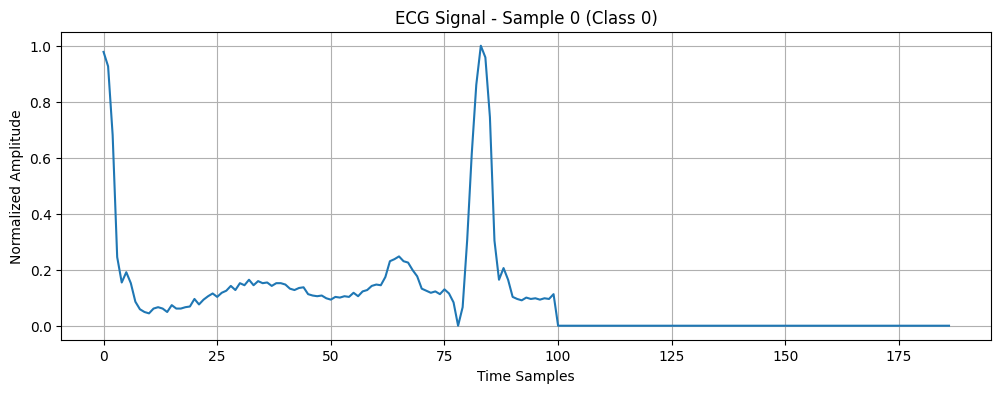

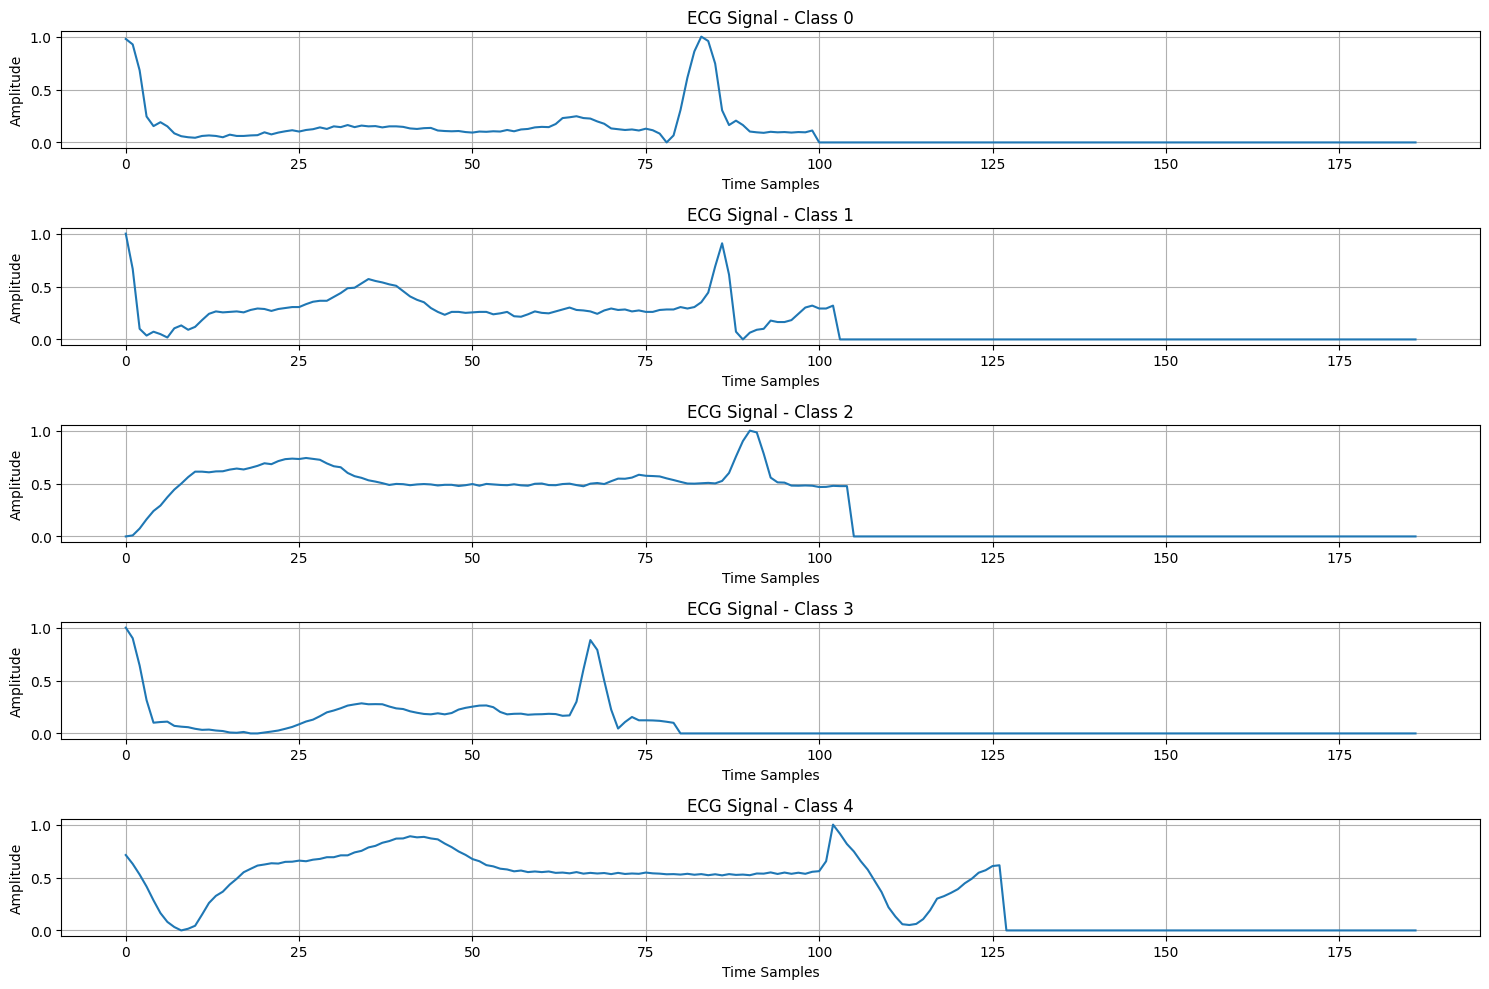

In [5]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 4))
plt.plot(X_raw[0], linewidth=1.5)
plt.title(f"ECG Signal - Sample 0 (Class {y[0]})")
plt.xlabel("Time Samples")
plt.ylabel("Normalized Amplitude")
plt.grid(True)
plt.show()

plt.figure(figsize=(15, 10))
for class_id in range(5):
    sample_index = np.where(y == class_id)[0][0]
    plt.subplot(5, 1, class_id + 1)
    plt.plot(X_raw[sample_index], linewidth=1.5)
    plt.title(f"ECG Signal - Class {class_id}")
    plt.xlabel("Time Samples")
    plt.ylabel("Amplitude")
    plt.grid(True)
plt.tight_layout()
plt.show()

Feature Extraction 1 – Statistical Features

In [6]:
from scipy.stats import skew, kurtosis
import time

def extract_statistical_features(X_data):
    start_time = time.time()
    features = []
    for row in X_data:
        row_features = [
            np.mean(row),
            np.std(row),
            np.max(row),
            np.min(row),
            np.ptp(row),
            skew(row),
            kurtosis(row)
        ]
        features.append(row_features)
    print(f"Statistical Extraction complete in {time.time() - start_time:.2f} seconds.")
    return np.array(features)

X_stat = extract_statistical_features(X_raw)
print(f"Statistical Features Shape: {X_stat.shape}")

Statistical Extraction complete in 149.62 seconds.
Statistical Features Shape: (109446, 7)


Feature Extraction 2 – Morphological Features

In [7]:
def extract_morphological_features(X_data):
    start_time = time.time()
    features = []
    for row in X_data:
        max_val = np.max(row)
        min_val = np.min(row)
        max_idx = np.argmax(row)
        min_idx = np.argmin(row)
        centered = row - np.mean(row)
        zero_crossings = np.sum(np.diff(np.sign(centered)) != 0)
        qrs_width = np.sum(row > (0.5 * max_val))
        row_features = [
            max_val,
            max_idx,
            min_val,
            min_idx,
            max_val - min_val,
            abs(max_idx - min_idx),
            np.sum(row ** 2),
            np.sum(np.abs(row)),
            zero_crossings,
            qrs_width,
            np.percentile(row, 25),
            np.percentile(row, 75)
        ]
        features.append(row_features)
    print(f"Morphological Extraction complete in {time.time() - start_time:.2f} seconds.")
    return np.array(features)

X_morph = extract_morphological_features(X_raw)
if X_morph.shape[0] == 12:
    X_morph = X_morph.T

print(f"Morphological Features Shape: {X_morph.shape}")

Morphological Extraction complete in 24.27 seconds.
Morphological Features Shape: (109446, 12)


SVM - Statistical Features

Verified X_features shape: (109446, 7)
Verified y shape: (109446,)
--------------------------------------------------
Starting 5-Fold Stratified CV with Balanced Linear SVC (Statistical Features)...
Fold 1 - Accuracy: 0.8061, Macro-F1: 0.3031
Fold 2 - Accuracy: 0.8034, Macro-F1: 0.2962
Fold 3 - Accuracy: 0.8043, Macro-F1: 0.2945
Fold 4 - Accuracy: 0.7988, Macro-F1: 0.2999
Fold 5 - Accuracy: 0.8038, Macro-F1: 0.2950

--- Final Fold Evaluation Details ---
Confusion Matrix:
 [[16745     2   496    20   854]
 [  492    29     0     0    35]
 [  973     6    67    16   385]
 [  157     1     1     0     2]
 [  840     0    12     3   753]]

Classification Report:
               precision    recall  f1-score   support

           N       0.87      0.92      0.90     18117
           S       0.76      0.05      0.10       556
           V       0.12      0.05      0.07      1447
           F       0.00      0.00      0.00       161
           Q       0.37      0.47      0.41      1608

    ac

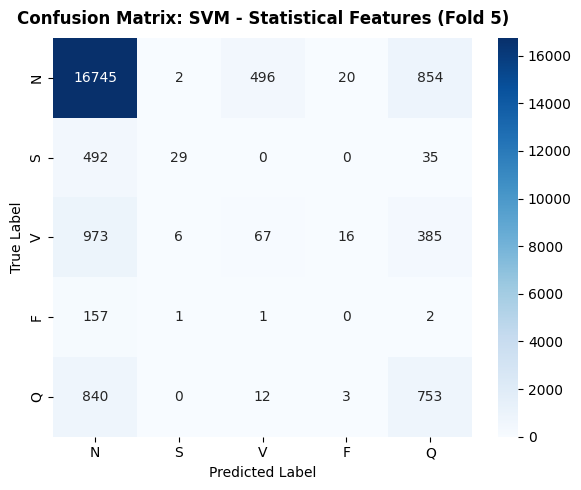


FINAL PROJECT METRICS (Mean ± Standard Deviation)
Accuracy:  0.8033 ± 0.0024
Macro-F1:  0.2977 ± 0.0033


In [11]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

print(f"Verified X_features shape: {X_stat.shape}")
print(f"Verified y shape: {y.shape}")
print("-" * 50)
print("Starting 5-Fold Stratified CV with Balanced Linear SVC (Statistical Features)...")

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

acc_scores = []
f1_scores = []

for fold, (train_idx, test_idx) in enumerate(skf.split(X_stat, y), 1):
    X_train, X_test = X_stat[train_idx], X_stat[test_idx]
    y_train, y_test = y[train_idx], y[test_idx]

    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)

    model = LinearSVC(class_weight='balanced', random_state=42, max_iter=1000, dual=False)
    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)

    acc = accuracy_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred, average='macro')

    acc_scores.append(acc)
    f1_scores.append(f1)

    print(f"Fold {fold} - Accuracy: {acc:.4f}, Macro-F1: {f1:.4f}")

    if fold == 5:
        cm = confusion_matrix(y_test, y_pred)
        print("\n--- Final Fold Evaluation Details ---")
        print("Confusion Matrix:\n", cm)
        print("\nClassification Report:\n", classification_report(y_test, y_pred, target_names=["N", "S", "V", "F", "Q"]))

        plt.figure(figsize=(6, 5))
        sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=["N", "S", "V", "F", "Q"], yticklabels=["N", "S", "V", "F", "Q"])
        plt.title("Confusion Matrix: SVM - Statistical Features (Fold 5)", fontsize=12, fontweight='bold', pad=10)
        plt.xlabel('Predicted Label')
        plt.ylabel('True Label')
        plt.tight_layout()
        plt.show()

print("\n" + "=" * 50)
print("FINAL PROJECT METRICS (Mean ± Standard Deviation)")
print("=" * 50)
print(f"Accuracy:  {np.mean(acc_scores):.4f} ± {np.std(acc_scores):.4f}")
print(f"Macro-F1:  {np.mean(f1_scores):.4f} ± {np.std(f1_scores):.4f}")

KNN - Statistical Features

Verified X_features shape: (109446, 7)
Verified y shape: (109446,)
--------------------------------------------------
Starting 5-Fold Stratified CV with KNN (Statistical Features)...
Fold 1 - Accuracy: 0.8944, Macro-F1: 0.6293
Fold 2 - Accuracy: 0.8927, Macro-F1: 0.6054
Fold 3 - Accuracy: 0.8924, Macro-F1: 0.6292
Fold 4 - Accuracy: 0.8951, Macro-F1: 0.6277
Fold 5 - Accuracy: 0.8962, Macro-F1: 0.6466

--- Final Fold Evaluation Details ---
Confusion Matrix:
 [[17473    99   268    36   241]
 [  321   202    19     1    13]
 [  682    22   676     6    61]
 [   83     0     6    71     1]
 [  365     7    40     0  1196]]

Classification Report:
               precision    recall  f1-score   support

           N       0.92      0.96      0.94     18117
           S       0.61      0.36      0.46       556
           V       0.67      0.47      0.55      1447
           F       0.62      0.44      0.52       161
           Q       0.79      0.74      0.77      1608

    accuracy          

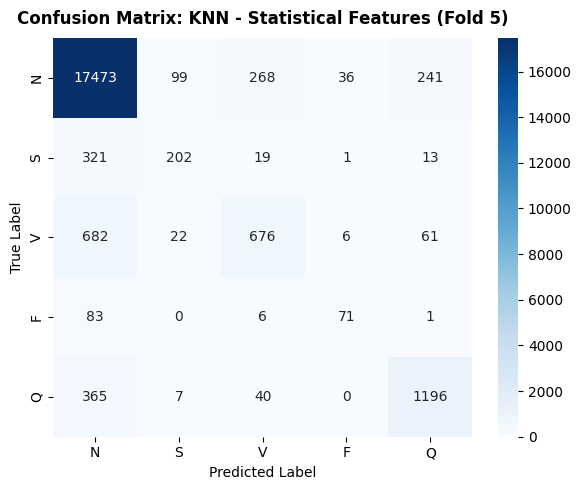


FINAL PROJECT METRICS (Mean ± Standard Deviation)
Accuracy:  0.8942 ± 0.0014
Macro-F1:  0.6276 ± 0.0131


In [12]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

print(f"Verified X_features shape: {X_stat.shape}")
print(f"Verified y shape: {y.shape}")
print("-" * 50)
print("Starting 5-Fold Stratified CV with KNN (Statistical Features)...")

acc_scores = []
f1_scores = []

for fold, (train_idx, test_idx) in enumerate(skf.split(X_stat, y), 1):
    X_train, X_test = X_stat[train_idx], X_stat[test_idx]
    y_train, y_test = y[train_idx], y[test_idx]

    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)

    model = KNeighborsClassifier(n_neighbors=5, weights='distance', n_jobs=-1)
    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)

    acc = accuracy_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred, average='macro')

    acc_scores.append(acc)
    f1_scores.append(f1)

    print(f"Fold {fold} - Accuracy: {acc:.4f}, Macro-F1: {f1:.4f}")

    if fold == 5:
        cm = confusion_matrix(y_test, y_pred)
        print("\n--- Final Fold Evaluation Details ---")
        print("Confusion Matrix:\n", cm)
        print("\nClassification Report:\n", classification_report(y_test, y_pred, target_names=["N", "S", "V", "F", "Q"]))

        plt.figure(figsize=(6, 5))
        sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=["N", "S", "V", "F", "Q"], yticklabels=["N", "S", "V", "F", "Q"])
        plt.title("Confusion Matrix: KNN - Statistical Features (Fold 5)", fontsize=12, fontweight='bold', pad=10)
        plt.xlabel('Predicted Label')
        plt.ylabel('True Label')
        plt.tight_layout()
        plt.show()

print("\n" + "=" * 50)
print("FINAL PROJECT METRICS (Mean ± Standard Deviation)")
print("=" * 50)
print(f"Accuracy:  {np.mean(acc_scores):.4f} ± {np.std(acc_scores):.4f}")
print(f"Macro-F1:  {np.mean(f1_scores):.4f} ± {np.std(f1_scores):.4f}")

Random Forest - Statistical Features

Verified X_features shape: (109446, 7)
Verified y shape: (109446,)
--------------------------------------------------
Starting 5-Fold Stratified CV with Balanced Random Forest (Statistical Features)...
Fold 1 - Accuracy: 0.9032, Macro-F1: 0.6217
Fold 2 - Accuracy: 0.9017, Macro-F1: 0.5972
Fold 3 - Accuracy: 0.8987, Macro-F1: 0.6037
Fold 4 - Accuracy: 0.9028, Macro-F1: 0.6142
Fold 5 - Accuracy: 0.9019, Macro-F1: 0.6097

--- Final Fold Evaluation Details ---
Confusion Matrix:
 [[17794    30   118    14   161]
 [  411   128     9     0     8]
 [  775     8   615     1    48]
 [  106     1     6    47     1]
 [  416     2    33     0  1157]]

Classification Report:
               precision    recall  f1-score   support

           N       0.91      0.98      0.95     18117
           S       0.76      0.23      0.35       556
           V       0.79      0.43      0.55      1447
           F       0.76      0.29      0.42       161
           Q       0.84      0.72      0.78      1608

   

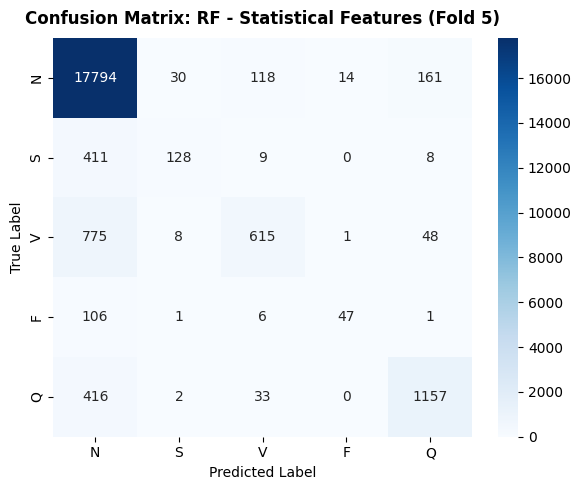


FINAL PROJECT METRICS (Mean ± Standard Deviation)
Accuracy:  0.9017 ± 0.0016
Macro-F1:  0.6093 ± 0.0085


In [13]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

print(f"Verified X_features shape: {X_stat.shape}")
print(f"Verified y shape: {y.shape}")
print("-" * 50)
print("Starting 5-Fold Stratified CV with Balanced Random Forest (Statistical Features)...")

acc_scores = []
f1_scores = []

for fold, (train_idx, test_idx) in enumerate(skf.split(X_stat, y), 1):
    X_train, X_test = X_stat[train_idx], X_stat[test_idx]
    y_train, y_test = y[train_idx], y[test_idx]

    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)

    model = RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=42, n_jobs=-1)
    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)

    acc = accuracy_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred, average='macro')

    acc_scores.append(acc)
    f1_scores.append(f1)

    print(f"Fold {fold} - Accuracy: {acc:.4f}, Macro-F1: {f1:.4f}")

    if fold == 5:
        cm = confusion_matrix(y_test, y_pred)
        print("\n--- Final Fold Evaluation Details ---")
        print("Confusion Matrix:\n", cm)
        print("\nClassification Report:\n", classification_report(y_test, y_pred, target_names=["N", "S", "V", "F", "Q"]))

        plt.figure(figsize=(6, 5))
        sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=["N", "S", "V", "F", "Q"], yticklabels=["N", "S", "V", "F", "Q"])
        plt.title("Confusion Matrix: RF - Statistical Features (Fold 5)", fontsize=12, fontweight='bold', pad=10)
        plt.xlabel('Predicted Label')
        plt.ylabel('True Label')
        plt.tight_layout()
        plt.show()

print("\n" + "=" * 50)
print("FINAL PROJECT METRICS (Mean ± Standard Deviation)")
print("=" * 50)
print(f"Accuracy:  {np.mean(acc_scores):.4f} ± {np.std(acc_scores):.4f}")
print(f"Macro-F1:  {np.mean(f1_scores):.4f} ± {np.std(f1_scores):.4f}")

 SVC (Morphological Features)

Verified X_features shape: (109446, 12)
Verified y shape: (109446,)
--------------------------------------------------
Starting 5-Fold Stratified CV with Balanced Linear SVC (Morphological Features)...
Fold 1 - Accuracy: 0.7916, Macro-F1: 0.3391
Fold 2 - Accuracy: 0.7877, Macro-F1: 0.3413
Fold 3 - Accuracy: 0.7900, Macro-F1: 0.3396
Fold 4 - Accuracy: 0.7832, Macro-F1: 0.3325
Fold 5 - Accuracy: 0.7837, Macro-F1: 0.3383

--- Final Fold Evaluation Details ---
Confusion Matrix:
 [[15997     8  1080   127   905]
 [  458    31    20     6    41]
 [  876     4   301     1   265]
 [  151     0     1     8     1]
 [  690     0    95     5   818]]

Classification Report:
               precision    recall  f1-score   support

           N       0.88      0.88      0.88     18117
           S       0.72      0.06      0.10       556
           V       0.20      0.21      0.20      1447
           F       0.05      0.05      0.05       161
           Q       0.40      0.51      0.45      1608

   

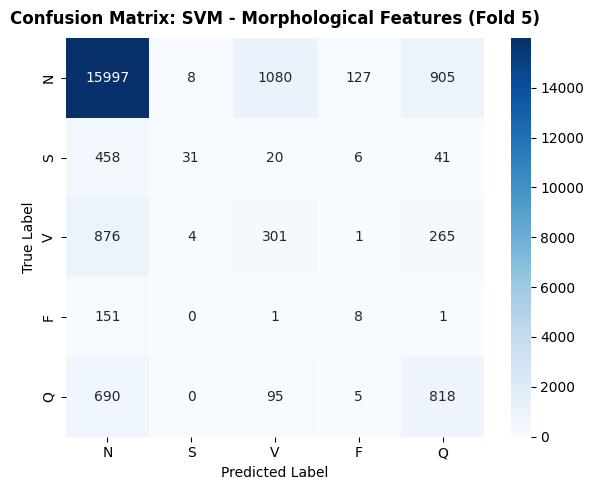


FINAL PROJECT METRICS (Mean ± Standard Deviation)
Accuracy:  0.7872 ± 0.0033
Macro-F1:  0.3382 ± 0.0030


In [14]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

print(f"Verified X_features shape: {X_morph.shape}")
print(f"Verified y shape: {y.shape}")
print("-" * 50)
print("Starting 5-Fold Stratified CV with Balanced Linear SVC (Morphological Features)...")

acc_scores = []
f1_scores = []

for fold, (train_idx, test_idx) in enumerate(skf.split(X_morph, y), 1):
    X_train, X_test = X_morph[train_idx], X_morph[test_idx]
    y_train, y_test = y[train_idx], y[test_idx]

    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)

    model = LinearSVC(class_weight='balanced', random_state=42, max_iter=1000, dual=False)
    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)

    acc = accuracy_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred, average='macro')

    acc_scores.append(acc)
    f1_scores.append(f1)

    print(f"Fold {fold} - Accuracy: {acc:.4f}, Macro-F1: {f1:.4f}")

    if fold == 5:
        cm = confusion_matrix(y_test, y_pred)
        print("\n--- Final Fold Evaluation Details ---")
        print("Confusion Matrix:\n", cm)
        print("\nClassification Report:\n", classification_report(y_test, y_pred, target_names=["N", "S", "V", "F", "Q"]))

        plt.figure(figsize=(6, 5))
        sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=["N", "S", "V", "F", "Q"], yticklabels=["N", "S", "V", "F", "Q"])
        plt.title("Confusion Matrix: SVM - Morphological Features (Fold 5)", fontsize=12, fontweight='bold', pad=10)
        plt.xlabel('Predicted Label')
        plt.ylabel('True Label')
        plt.tight_layout()
        plt.show()

print("\n" + "=" * 50)
print("FINAL PROJECT METRICS (Mean ± Standard Deviation)")
print("=" * 50)
print(f"Accuracy:  {np.mean(acc_scores):.4f} ± {np.std(acc_scores):.4f}")
print(f"Macro-F1:  {np.mean(f1_scores):.4f} ± {np.std(f1_scores):.4f}")

KNN - Morphological Features

Verified X_features shape: (109446, 12)
Verified y shape: (109446,)
--------------------------------------------------
Starting 5-Fold Stratified CV with KNN (Morphological Features)...
Fold 1 - Accuracy: 0.9513, Macro-F1: 0.8098
Fold 2 - Accuracy: 0.9482, Macro-F1: 0.7783
Fold 3 - Accuracy: 0.9480, Macro-F1: 0.7924
Fold 4 - Accuracy: 0.9495, Macro-F1: 0.8018
Fold 5 - Accuracy: 0.9506, Macro-F1: 0.8065

--- Final Fold Evaluation Details ---
Confusion Matrix:
 [[17846    59    85    25   102]
 [  236   310    10     0     0]
 [  227     7  1179    10    24]
 [   54     0    12    95     0]
 [  210     2    18     0  1378]]

Classification Report:
               precision    recall  f1-score   support

           N       0.96      0.99      0.97     18117
           S       0.82      0.56      0.66       556
           V       0.90      0.81      0.86      1447
           F       0.73      0.59      0.65       161
           Q       0.92      0.86      0.89      1608

    accuracy       

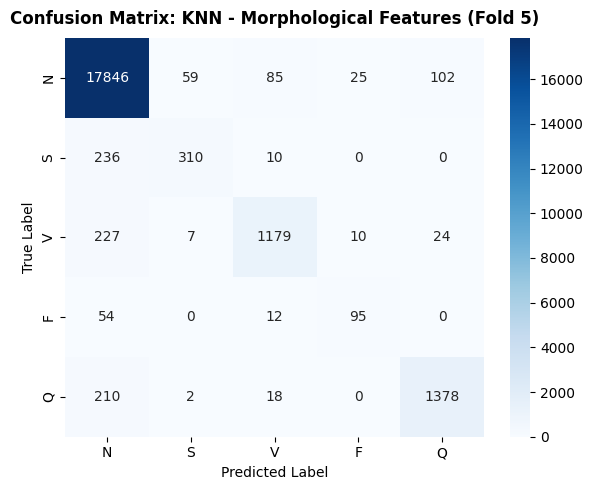


FINAL PROJECT METRICS (Mean ± Standard Deviation)
Accuracy:  0.9495 ± 0.0013
Macro-F1:  0.7977 ± 0.0114


In [15]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

print(f"Verified X_features shape: {X_morph.shape}")
print(f"Verified y shape: {y.shape}")
print("-" * 50)
print("Starting 5-Fold Stratified CV with KNN (Morphological Features)...")

acc_scores = []
f1_scores = []

for fold, (train_idx, test_idx) in enumerate(skf.split(X_morph, y), 1):
    X_train, X_test = X_morph[train_idx], X_morph[test_idx]
    y_train, y_test = y[train_idx], y[test_idx]

    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)

    model = KNeighborsClassifier(n_neighbors=5, weights='distance', n_jobs=-1)
    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)

    acc = accuracy_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred, average='macro')

    acc_scores.append(acc)
    f1_scores.append(f1)

    print(f"Fold {fold} - Accuracy: {acc:.4f}, Macro-F1: {f1:.4f}")

    if fold == 5:
        cm = confusion_matrix(y_test, y_pred)
        print("\n--- Final Fold Evaluation Details ---")
        print("Confusion Matrix:\n", cm)
        print("\nClassification Report:\n", classification_report(y_test, y_pred, target_names=["N", "S", "V", "F", "Q"]))

        plt.figure(figsize=(6, 5))
        sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=["N", "S", "V", "F", "Q"], yticklabels=["N", "S", "V", "F", "Q"])
        plt.title("Confusion Matrix: KNN - Morphological Features (Fold 5)", fontsize=12, fontweight='bold', pad=10)
        plt.xlabel('Predicted Label')
        plt.ylabel('True Label')
        plt.tight_layout()
        plt.show()

print("\n" + "=" * 50)
print("FINAL PROJECT METRICS (Mean ± Standard Deviation)")
print("=" * 50)
print(f"Accuracy:  {np.mean(acc_scores):.4f} ± {np.std(acc_scores):.4f}")
print(f"Macro-F1:  {np.mean(f1_scores):.4f} ± {np.std(f1_scores):.4f}")

Random Forest - Morphological Features

Verified X_features shape: (109446, 12)
Verified y shape: (109446,)
--------------------------------------------------
Starting 5-Fold Stratified CV with Balanced Random Forest (Morphological Features)...
Fold 1 - Accuracy: 0.9609, Macro-F1: 0.8327
Fold 2 - Accuracy: 0.9589, Macro-F1: 0.8080
Fold 3 - Accuracy: 0.9589, Macro-F1: 0.8192
Fold 4 - Accuracy: 0.9591, Macro-F1: 0.8272
Fold 5 - Accuracy: 0.9619, Macro-F1: 0.8340

--- Final Fold Evaluation Details ---
Confusion Matrix:
 [[18009    17    46     9    36]
 [  241   310     5     0     0]
 [  194     1  1237     8     7]
 [   57     0    14    90     0]
 [  191     1     6     0  1410]]

Classification Report:
               precision    recall  f1-score   support

           N       0.96      0.99      0.98     18117
           S       0.94      0.56      0.70       556
           V       0.95      0.85      0.90      1447
           F       0.84      0.56      0.67       161
           Q       0.97      0.88      0.92      1608



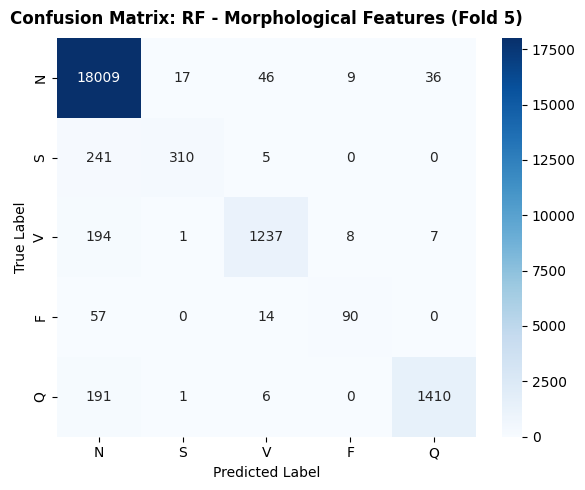


FINAL PROJECT METRICS (Mean ± Standard Deviation)
Accuracy:  0.9599 ± 0.0013
Macro-F1:  0.8242 ± 0.0097


In [16]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

print(f"Verified X_features shape: {X_morph.shape}")
print(f"Verified y shape: {y.shape}")
print("-" * 50)
print("Starting 5-Fold Stratified CV with Balanced Random Forest (Morphological Features)...")

acc_scores = []
f1_scores = []

for fold, (train_idx, test_idx) in enumerate(skf.split(X_morph, y), 1):
    X_train, X_test = X_morph[train_idx], X_morph[test_idx]
    y_train, y_test = y[train_idx], y[test_idx]

    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)

    model = RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=42, n_jobs=-1)
    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)

    acc = accuracy_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred, average='macro')

    acc_scores.append(acc)
    f1_scores.append(f1)

    print(f"Fold {fold} - Accuracy: {acc:.4f}, Macro-F1: {f1:.4f}")

    if fold == 5:
        cm = confusion_matrix(y_test, y_pred)
        print("\n--- Final Fold Evaluation Details ---")
        print("Confusion Matrix:\n", cm)
        print("\nClassification Report:\n", classification_report(y_test, y_pred, target_names=["N", "S", "V", "F", "Q"]))

        plt.figure(figsize=(6, 5))
        sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=["N", "S", "V", "F", "Q"], yticklabels=["N", "S", "V", "F", "Q"])
        plt.title("Confusion Matrix: RF - Morphological Features (Fold 5)", fontsize=12, fontweight='bold', pad=10)
        plt.xlabel('Predicted Label')
        plt.ylabel('True Label')
        plt.tight_layout()
        plt.show()

print("\n" + "=" * 50)
print("FINAL PROJECT METRICS (Mean ± Standard Deviation)")
print("=" * 50)
print(f"Accuracy:  {np.mean(acc_scores):.4f} ± {np.std(acc_scores):.4f}")
print(f"Macro-F1:  {np.mean(f1_scores):.4f} ± {np.std(f1_scores):.4f}")

Discrete Wavelet Transform - Random Forest

Extracting DWT Features (Takes ~45 seconds)...
Extraction complete in 24.20 seconds.

Verified X_features shape: (109446, 20)
Verified y shape: (109446,)
--------------------------------------------------
Starting 5-Fold Stratified CV with Balanced Random Forest (DWT Features)...
Fold 1 - Accuracy: 0.9527, Macro-F1: 0.7807
Fold 2 - Accuracy: 0.9515, Macro-F1: 0.7591
Fold 3 - Accuracy: 0.9513, Macro-F1: 0.7640
Fold 4 - Accuracy: 0.9509, Macro-F1: 0.7743
Fold 5 - Accuracy: 0.9525, Macro-F1: 0.7727

--- Final Fold Evaluation Details ---
Confusion Matrix:
 [[18016    11    63     6    21]
 [  302   249     4     1     0]
 [  322     0  1100     4    21]
 [   89     0    11    61     0]
 [  157     0    27     0  1424]]

Classification Report:
               precision    recall  f1-score   support

           N       0.95      0.99      0.97     18117
           S       0.96      0.45      0.61       556
           V       0.91      0.76      0.83      1447
           F       0.85      0.38

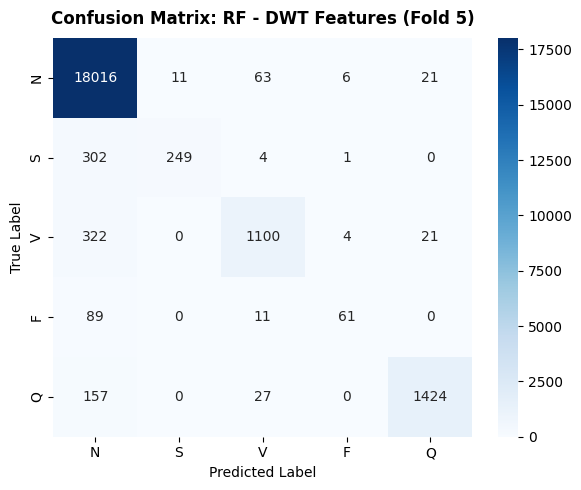


FINAL PROJECT METRICS (Mean ± Standard Deviation)
Accuracy:  0.9518 ± 0.0007
Macro-F1:  0.7702 ± 0.0077


In [17]:
import pywt
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import time
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
import warnings

warnings.filterwarnings('ignore')

def extract_dwt_features(X_data):
    print("Extracting DWT Features (Takes ~45 seconds)...")
    start_time = time.time()
    features = []
    for row in X_data:
        coeffs = pywt.wavedec(row, 'db4', level=4)
        row_features = []
        for band in coeffs:
            row_features.extend([
                np.mean(band),
                np.std(band),
                np.sum(np.square(band)),
                np.max(band)
            ])
        features.append(row_features)
    print(f"Extraction complete in {time.time() - start_time:.2f} seconds.\n")
    return np.array(features)

y = full_df.iloc[:, -1].values
X_dwt = extract_dwt_features(X_raw)

if X_dwt.shape[0] == 20:
    X_dwt = X_dwt.T

print(f"Verified X_features shape: {X_dwt.shape}")
print(f"Verified y shape: {y.shape}")
print("-" * 50)
print("Starting 5-Fold Stratified CV with Balanced Random Forest (DWT Features)...")

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
acc_scores = []
f1_scores = []

for fold, (train_idx, test_idx) in enumerate(skf.split(X_dwt, y), 1):
    X_train, X_test = X_dwt[train_idx], X_dwt[test_idx]
    y_train, y_test = y[train_idx], y[test_idx]

    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)

    model = RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=42, n_jobs=-1)
    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)

    acc = accuracy_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred, average='macro')

    acc_scores.append(acc)
    f1_scores.append(f1)

    print(f"Fold {fold} - Accuracy: {acc:.4f}, Macro-F1: {f1:.4f}")

    if fold == 5:
        cm = confusion_matrix(y_test, y_pred)
        print("\n--- Final Fold Evaluation Details ---")
        print("Confusion Matrix:\n", cm)
        print("\nClassification Report:\n", classification_report(y_test, y_pred, target_names=["N", "S", "V", "F", "Q"]))

        plt.figure(figsize=(6, 5))
        sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=["N", "S", "V", "F", "Q"], yticklabels=["N", "S", "V", "F", "Q"])
        plt.title("Confusion Matrix: RF - DWT Features (Fold 5)", fontsize=12, fontweight='bold', pad=10)
        plt.xlabel('Predicted Label')
        plt.ylabel('True Label')
        plt.tight_layout()
        plt.show()

print("\n" + "=" * 50)
print("FINAL PROJECT METRICS (Mean ± Standard Deviation)")
print("=" * 50)
print(f"Accuracy:  {np.mean(acc_scores):.4f} ± {np.std(acc_scores):.4f}")
print(f"Macro-F1:  {np.mean(f1_scores):.4f} ± {np.std(f1_scores):.4f}")

Discrete Wavelet Transform - KNN

Verified X_features shape: (109446, 20)
Verified y shape: (109446,)
--------------------------------------------------
Starting 5-Fold Stratified CV with KNN (DWT Features)...
Fold 1 - Accuracy: 0.9580, Macro-F1: 0.8231
Fold 2 - Accuracy: 0.9560, Macro-F1: 0.8024
Fold 3 - Accuracy: 0.9543, Macro-F1: 0.8035
Fold 4 - Accuracy: 0.9570, Macro-F1: 0.8171
Fold 5 - Accuracy: 0.9581, Macro-F1: 0.8185

--- Final Fold Evaluation Details ---
Confusion Matrix:
 [[17896    37   117    17    50]
 [  240   300    12     2     2]
 [  203     4  1199     8    33]
 [   47     0    18    95     1]
 [   96     1    25     4  1482]]

Classification Report:
               precision    recall  f1-score   support

           N       0.97      0.99      0.98     18117
           S       0.88      0.54      0.67       556
           V       0.87      0.83      0.85      1447
           F       0.75      0.59      0.66       161
           Q       0.95      0.92      0.93      1608

    accuracy                 

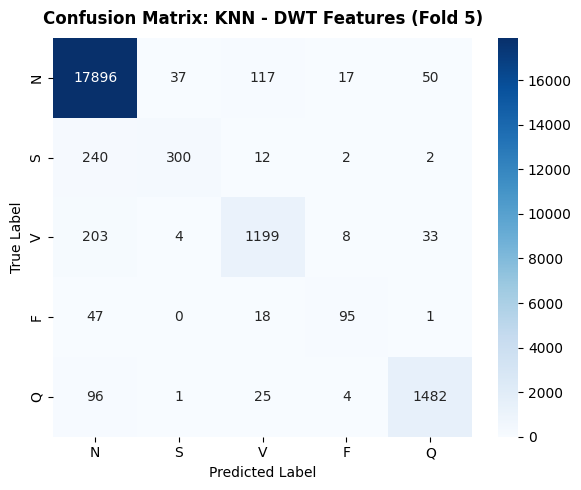


FINAL PROJECT METRICS (Mean ± Standard Deviation)
Accuracy:  0.9567 ± 0.0014
Macro-F1:  0.8129 ± 0.0084


In [18]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

if 'X_dwt' in locals() and X_dwt.shape[0] == 20:
    X_dwt = X_dwt.T

print(f"Verified X_features shape: {X_dwt.shape}")
print(f"Verified y shape: {y.shape}")
print("-" * 50)
print("Starting 5-Fold Stratified CV with KNN (DWT Features)...")

acc_scores = []
f1_scores = []

for fold, (train_idx, test_idx) in enumerate(skf.split(X_dwt, y), 1):
    X_train, X_test = X_dwt[train_idx], X_dwt[test_idx]
    y_train, y_test = y[train_idx], y[test_idx]

    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)

    model = KNeighborsClassifier(n_neighbors=5, weights='distance', n_jobs=-1)
    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)

    acc = accuracy_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred, average='macro')

    acc_scores.append(acc)
    f1_scores.append(f1)

    print(f"Fold {fold} - Accuracy: {acc:.4f}, Macro-F1: {f1:.4f}")

    if fold == 5:
        cm = confusion_matrix(y_test, y_pred)
        print("\n--- Final Fold Evaluation Details ---")
        print("Confusion Matrix:\n", cm)
        print("\nClassification Report:\n", classification_report(y_test, y_pred, target_names=["N", "S", "V", "F", "Q"]))

        plt.figure(figsize=(6, 5))
        sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=["N", "S", "V", "F", "Q"], yticklabels=["N", "S", "V", "F", "Q"])
        plt.title("Confusion Matrix: KNN - DWT Features (Fold 5)", fontsize=12, fontweight='bold', pad=10)
        plt.xlabel('Predicted Label')
        plt.ylabel('True Label')
        plt.tight_layout()
        plt.show()

print("\n" + "=" * 50)
print("FINAL PROJECT METRICS (Mean ± Standard Deviation)")
print("=" * 50)
print(f"Accuracy:  {np.mean(acc_scores):.4f} ± {np.std(acc_scores):.4f}")
print(f"Macro-F1:  {np.mean(f1_scores):.4f} ± {np.std(f1_scores):.4f}")

Combined (Stat + Morph + DWT) - KNN

Verified X_combined shape: (109446, 39)
Verified y shape: (109446,)
--------------------------------------------------
Starting 5-Fold Stratified CV with KNN (All Combined Features)...
Fold 1 - Accuracy: 0.9677, Macro-F1: 0.8530
Fold 2 - Accuracy: 0.9649, Macro-F1: 0.8326
Fold 3 - Accuracy: 0.9657, Macro-F1: 0.8437
Fold 4 - Accuracy: 0.9670, Macro-F1: 0.8479
Fold 5 - Accuracy: 0.9682, Macro-F1: 0.8503

--- Final Fold Evaluation Details ---
Confusion Matrix:
 [[17969    38    66    13    31]
 [  223   319    13     1     0]
 [  130     5  1290    12    10]
 [   34     1    21   104     1]
 [   77     0    20     0  1511]]

Classification Report:
               precision    recall  f1-score   support

           N       0.97      0.99      0.98     18117
           S       0.88      0.57      0.69       556
           V       0.91      0.89      0.90      1447
           F       0.80      0.65      0.71       161
           Q       0.97      0.94      0.96      1608

    accuracy        

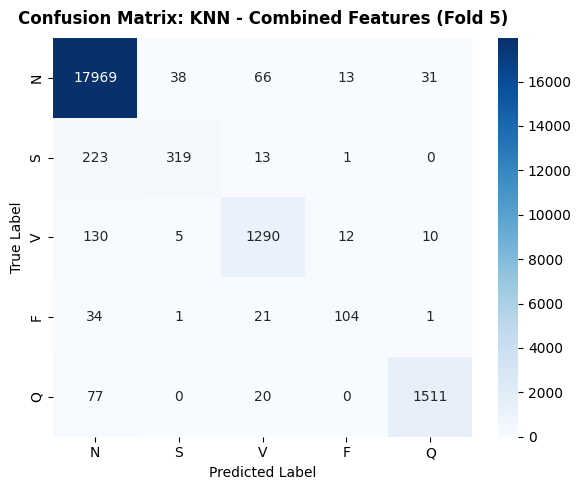


FINAL PROJECT METRICS (Mean ± Standard Deviation)
Accuracy:  0.9667 ± 0.0012
Macro-F1:  0.8455 ± 0.0071


In [19]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

# 1. Combine all features horizontally
# This will result in 7 (stat) + 12 (morph) + 20 (dwt) = 39 total features
X_combined = np.hstack((X_stat, X_morph, X_dwt))

print(f"Verified X_combined shape: {X_combined.shape}")
print(f"Verified y shape: {y.shape}")
print("-" * 50)
print("Starting 5-Fold Stratified CV with KNN (All Combined Features)...")

# 2. Initialize StratifiedKFold
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

acc_scores = []
f1_scores = []

# 3. Run the Cross-Validation loop
for fold, (train_idx, test_idx) in enumerate(skf.split(X_combined, y), 1):
    X_train, X_test = X_combined[train_idx], X_combined[test_idx]
    y_train, y_test = y[train_idx], y[test_idx]

    # Scale features
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)

    # Train KNN
    model = KNeighborsClassifier(n_neighbors=5, weights='distance', n_jobs=-1)
    model.fit(X_train_scaled, y_train)

    # Predict and evaluate
    y_pred = model.predict(X_test_scaled)

    acc = accuracy_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred, average='macro')

    acc_scores.append(acc)
    f1_scores.append(f1)

    print(f"Fold {fold} - Accuracy: {acc:.4f}, Macro-F1: {f1:.4f}")

    # Plot details for the final fold
    if fold == 5:
        cm = confusion_matrix(y_test, y_pred)
        print("\n--- Final Fold Evaluation Details ---")
        print("Confusion Matrix:\n", cm)
        print("\nClassification Report:\n", classification_report(y_test, y_pred, target_names=["N", "S", "V", "F", "Q"]))

        plt.figure(figsize=(6, 5))
        sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=["N", "S", "V", "F", "Q"], yticklabels=["N", "S", "V", "F", "Q"])
        plt.title("Confusion Matrix: KNN - Combined Features (Fold 5)", fontsize=12, fontweight='bold', pad=10)
        plt.xlabel('Predicted Label')
        plt.ylabel('True Label')
        plt.tight_layout()
        plt.show()

print("\n" + "=" * 50)
print("FINAL PROJECT METRICS (Mean ± Standard Deviation)")
print("=" * 50)
print(f"Accuracy:  {np.mean(acc_scores):.4f} ± {np.std(acc_scores):.4f}")
print(f"Macro-F1:  {np.mean(f1_scores):.4f} ± {np.std(f1_scores):.4f}")

Combined (Stat + Morph + DWT) - Random forest

Verified X_combined shape: (109446, 39)
Verified y shape: (109446,)
--------------------------------------------------
Starting 5-Fold Stratified CV with Balanced Random Forest (All Combined Features)...
Fold 1 - Accuracy: 0.9708, Macro-F1: 0.8715
Fold 2 - Accuracy: 0.9685, Macro-F1: 0.8378
Fold 3 - Accuracy: 0.9683, Macro-F1: 0.8490
Fold 4 - Accuracy: 0.9686, Macro-F1: 0.8542
Fold 5 - Accuracy: 0.9700, Macro-F1: 0.8601

--- Final Fold Evaluation Details ---
Confusion Matrix:
 [[18082     6    22     3     4]
 [  234   314     8     0     0]
 [  173     0  1260     9     5]
 [   48     0    13   100     0]
 [  122     0    10     0  1476]]

Classification Report:
               precision    recall  f1-score   support

           N       0.97      1.00      0.98     18117
           S       0.98      0.56      0.72       556
           V       0.96      0.87      0.91      1447
           F       0.89      0.62      0.73       161
           Q       0.99      0.92      0.95      1608

 

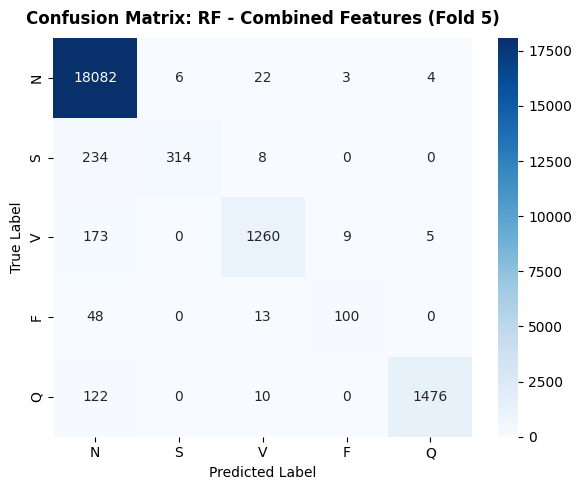


FINAL PROJECT METRICS (Mean ± Standard Deviation)
Accuracy:  0.9692 ± 0.0010
Macro-F1:  0.8545 ± 0.0112


In [21]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

# 1. Ensure features are combined (already done in previous cell, but safe to keep)
X_combined = np.hstack((X_stat, X_morph, X_dwt))

print(f"Verified X_combined shape: {X_combined.shape}")
print(f"Verified y shape: {y.shape}")
print("-" * 50)
print("Starting 5-Fold Stratified CV with Balanced Random Forest (All Combined Features)...")

# 2. Initialize StratifiedKFold
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

acc_scores = []
f1_scores = []

# 3. Run the Cross-Validation loop
for fold, (train_idx, test_idx) in enumerate(skf.split(X_combined, y), 1):
    X_train, X_test = X_combined[train_idx], X_combined[test_idx]
    y_train, y_test = y[train_idx], y[test_idx]

    # Scale features
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)

    # Train Random Forest (using your previous RF parameters)
    model = RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=42, n_jobs=-1)
    model.fit(X_train_scaled, y_train)

    # Predict and evaluate
    y_pred = model.predict(X_test_scaled)

    acc = accuracy_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred, average='macro')

    acc_scores.append(acc)
    f1_scores.append(f1)

    print(f"Fold {fold} - Accuracy: {acc:.4f}, Macro-F1: {f1:.4f}")

    # Plot details for the final fold
    if fold == 5:
        cm = confusion_matrix(y_test, y_pred)
        print("\n--- Final Fold Evaluation Details ---")
        print("Confusion Matrix:\n", cm)
        print("\nClassification Report:\n", classification_report(y_test, y_pred, target_names=["N", "S", "V", "F", "Q"]))

        plt.figure(figsize=(6, 5))
        sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=["N", "S", "V", "F", "Q"], yticklabels=["N", "S", "V", "F", "Q"])
        plt.title("Confusion Matrix: RF - Combined Features (Fold 5)", fontsize=12, fontweight='bold', pad=10)
        plt.xlabel('Predicted Label')
        plt.ylabel('True Label')
        plt.tight_layout()
        plt.show()

print("\n" + "=" * 50)
print("FINAL PROJECT METRICS (Mean ± Standard Deviation)")
print("=" * 50)
print(f"Accuracy:  {np.mean(acc_scores):.4f} ± {np.std(acc_scores):.4f}")
print(f"Macro-F1:  {np.mean(f1_scores):.4f} ± {np.std(f1_scores):.4f}")